### Display a stacked bar chart comparing sex vs target using only raw Matplotlib patches, ensuring proper alignment, color coding, and proportion calculations without using high-level bar chart functions.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [4]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [5]:
print(df["sex"].unique())
print(df["target"].unique())

[1 0]
[1 0]


In [6]:
sex_values = df["sex"].unique()
target_values = df["target"].unique()

counts = {}

for sex in sex_values:
    counts[sex] = {}

    for target in target_values:
        count = 0

        for i in range(len(df)):
            if df["sex"].iloc[i] == sex and df["target"].iloc[i] == target:
                count += 1

        counts[sex][target] = count

print(counts)

{np.int64(1): {np.int64(1): 93, np.int64(0): 114}, np.int64(0): {np.int64(1): 72, np.int64(0): 24}}


In [7]:
proportions = {}

for sex in sex_values:

    total = sum(counts[sex].values())
    proportions[sex] = {}

    for target in target_values:
        proportions[sex][target] = counts[sex][target] / total

print(proportions)

{np.int64(1): {np.int64(1): 0.4492753623188406, np.int64(0): 0.5507246376811594}, np.int64(0): {np.int64(1): 0.75, np.int64(0): 0.25}}


In [8]:
for sex in sex_values:

    print("Sex:", sex)

    for target in target_values:
        value = proportions[sex][target] * 100
        print("Target", target, ":", round(value, 1), "%")

Sex: 1
Target 1 : 44.9 %
Target 0 : 55.1 %
Sex: 0
Target 1 : 75.0 %
Target 0 : 25.0 %


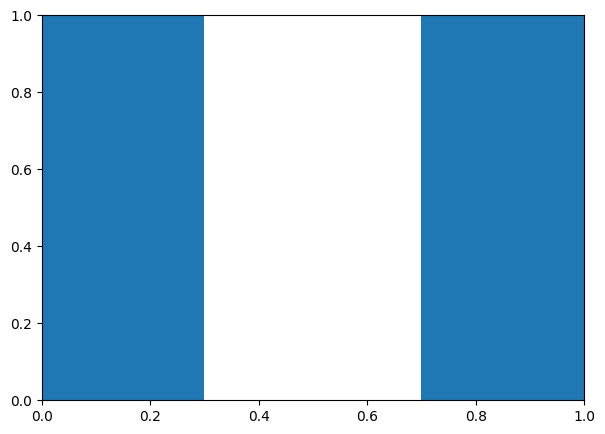

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))

width = 0.6

for i, sex in enumerate(sex_values):

    bottom = 0

    for target in target_values:

        height = proportions[sex][target]

        patch = Rectangle(
            (i - width / 2, bottom),
            width,
            height
        )

        ax.add_patch(patch)

        bottom += height

In [10]:
ax.set_xlim(-0.5, len(sex_values) - 0.5)
ax.set_ylim(0, 1)

ax.set_xticks(range(len(sex_values)))
ax.set_xticklabels(sex_values)

ax.set_xlabel("Sex")
ax.set_ylabel("Proportion")

ax.set_title("Sex vs Target - Stacked Bar Chart")

Text(0.5, 1.0, 'Sex vs Target - Stacked Bar Chart')

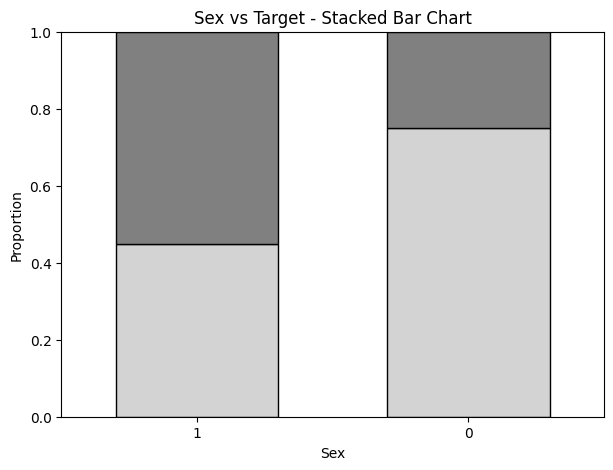

In [11]:
colors = ["lightgray", "gray"]

fig, ax = plt.subplots(figsize=(7, 5))

width = 0.6

for i, sex in enumerate(sex_values):

    bottom = 0

    for j, target in enumerate(target_values):

        height = proportions[sex][target]

        patch = Rectangle(
            (i - width / 2, bottom),
            width,
            height,
            facecolor=colors[j],
            edgecolor="black"
        )

        ax.add_patch(patch)

        bottom += height

ax.set_xlim(-0.5, len(sex_values) - 0.5)
ax.set_ylim(0, 1)

ax.set_xticks(range(len(sex_values)))
ax.set_xticklabels(sex_values)

ax.set_xlabel("Sex")
ax.set_ylabel("Proportion")

ax.set_title("Sex vs Target - Stacked Bar Chart")

plt.show()

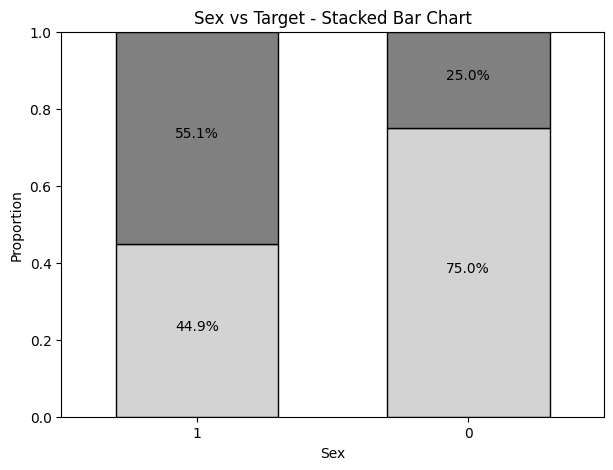

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

width = 0.6

for i, sex in enumerate(sex_values):

    bottom = 0

    for j, target in enumerate(target_values):

        height = proportions[sex][target]

        patch = Rectangle(
            (i - width / 2, bottom),
            width,
            height,
            facecolor=colors[j],
            edgecolor="black"
        )

        ax.add_patch(patch)

        if height > 0:
            ax.text(
                i,
                bottom + height / 2,
                str(round(height * 100, 1)) + "%",
                ha="center"
            )

        bottom += height

ax.set_xlim(-0.5, len(sex_values) - 0.5)
ax.set_ylim(0, 1)

ax.set_xticks(range(len(sex_values)))
ax.set_xticklabels(sex_values)

ax.set_xlabel("Sex")
ax.set_ylabel("Proportion")

ax.set_title("Sex vs Target - Stacked Bar Chart")

plt.show()